# Stage A on the Hu & Ma videos: repeatability, the two Pitch Factors, and the funding decision

Companion to [hu_ma_reannotation_oct7.md](../../docs/results/stage_A/hu_ma_reannotation_oct7.md) and to Hu & Ma
(2025, *Journal of Finance*), Tables II to IV. This notebook **computes** everything from a Stage A rating run and
a ranking run of the Hu & Ma accelerator videos: how well the replicate ratings agree (ICC), the Pitch Factor built
from the ten ratings and the one built from the forced-ranking scores, how far the two agree (Spearman), and the
relation of each to the accelerator's funding decision. It calls the same functions as
`scripts/analysis/analyze_hu_ma_stage_a.py`, so you can change a setting and run it again without touching any code.

**How to use this notebook**

1. Pick the kernel: choose the project's `.venv` Python (in Jupyter: *Kernel → Change kernel*; in VS Code: *Select Kernel*).
2. Edit the **configuration cell** just below. It is the only cell you need to change: name the rating run and the
   ranking run to analyse (folder names under `runs/`).
3. *Kernel → Restart & Run All*. It takes a few seconds and makes **no model calls**.

It reads the runs only and **never changes annotation files**. With `EXPORT = False` (the committed default) it writes
nothing; with `EXPORT = True` it writes the tables and a summary under `runs/<rating run>/analysis/<ANALYSIS_ID>/`.
Every number here is model-coded and not human-validated.

In [1]:
# ===== CONFIGURATION — the only cell you need to edit. Then: Kernel > Restart & Run All =====

STAGE_A_RUN_NAME = "stage_a_pitch_factor_20261008_004807"   # the rating run: a folder name under runs/ (or a full path); needs tables/annotations.parquet
RANK_RUN_NAME = "stage_a_hu_ma_ranking_v3dev8"               # the ranking run (folder under runs/ with ranking/scores.csv); None = ratings only
OUTCOMES_CSV = "data/hu-ma/funding_outcomes.csv"             # the funding labels, relative to the repository root (or a full path)
HU_MA_PITCH_FACTOR_CSV = "data/hu-ma/pitch_factor.csv"       # Hu & Ma's Pitch Factor and ten features from their code on the same videos; None = skip section 5
ANALYSIS_ID = "notebook"                                     # folder name for the files written when EXPORT is True:
                                                             #   runs/<rating run>/analysis/<ANALYSIS_ID>/  (letters, digits, . _ - only)
EXPORT = False                                               # True = write the tables and summary there; False = write nothing

In [2]:
# Setup and computation: finds the project folder, reads the two runs, and computes everything below. Nothing to edit here.
import re
import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "analysis" / "hu_ma_funding.py").exists())
sys.path.insert(0, str(REPO))
from IPython.display import display
import pandas as pd
from analysis import hu_ma_funding as hm
from analysis.panel_explorer import resolve_run

pd.set_option("display.width", 200, "display.max_columns", 40, "display.precision", 3)
STAGE_A_RUN = resolve_run(STAGE_A_RUN_NAME)
RANK_RUN = resolve_run(RANK_RUN_NAME) if RANK_RUN_NAME else None
OUTCOMES = Path(OUTCOMES_CSV) if Path(OUTCOMES_CSV).is_absolute() else REPO / OUTCOMES_CSV
HU_MA = None if not HU_MA_PITCH_FACTOR_CSV else (Path(HU_MA_PITCH_FACTOR_CSV) if Path(HU_MA_PITCH_FACTOR_CSV).is_absolute() else REPO / HU_MA_PITCH_FACTOR_CSV)
ANNOTATIONS = STAGE_A_RUN / "tables" / "annotations.parquet"
SCORES = RANK_RUN / "ranking" / "scores.csv" if RANK_RUN else None
assert ANNOTATIONS.exists(), f"{ANNOTATIONS} is missing: run scripts/aggregate.py --config configs/stage_a.yaml first"
assert SCORES is None or SCORES.exists(), f"{SCORES} is missing: the ranking run has not completed"
assert HU_MA is None or HU_MA.exists(), f"{HU_MA} is missing: set HU_MA_PITCH_FACTOR_CSV to None to skip section 5"
assert re.fullmatch(r"[A-Za-z0-9._-]+", ANALYSIS_ID), "ANALYSIS_ID may use letters, digits, . _ - only"
A = hm.compute(ANNOTATIONS, SCORES, OUTCOMES, provenance=hm.run_provenance(STAGE_A_RUN, RANK_RUN), hu_ma_csv=HU_MA)
S = A.summary
print(f"Rating run: {STAGE_A_RUN.name}   ranking run: {RANK_RUN.name if RANK_RUN else 'none'}   "
      f"Hu & Ma Pitch Factor file: {HU_MA.name if HU_MA else 'none'}")
print(f"Videos in the outcomes file: {S['videos_in_outcomes_file']}; with a 0/1 label: {S['videos_with_outcome_label']}; "
      f"accepted: {S['acceptances']}; rated: {S['videos_rated']}; ranked: {S['videos_ranked']}.")

Rating run: stage_a_pitch_factor_20261008_004807   ranking run: stage_a_hu_ma_ranking_v3dev8   Hu & Ma Pitch Factor file: pitch_factor.csv
Videos in the outcomes file: 50; with a 0/1 label: 49; accepted: 3; rated: 50; ranked: 50.


## 1. Provenance

**What this shows.** What the two runs recorded about themselves: the model and prompt hash of the rating run, how
many rating units finished and failed, the ranking design (batch size, appearances per video, repeated pairs), the
instrument release, and the calls and tokens each run spent.

**What it does not show.** Nothing here says whether the annotations are right; it says which instrument produced
them and that the runs completed.

In [3]:
display(hm.provenance_table(S["provenance"]))
display(hm.acceptance_table(A))

,item,value
0,stage_a_run,stage_a_pitch_factor_20261008_004807
1,stage_a_model,gemini-3.1-pro-preview
2,stage_a_passes.holistic.done,250
3,stage_a_passes.holistic.failed,0
4,stage_a_passes.holistic.prompt_hash,6a7750e44d39b335
...,...,...
80,rank_calls.calls,40
81,rank_calls.ok,40
82,rank_calls.input_tokens,1019076
83,rank_calls.output_tokens,35017


,accelerator,videos,labelled,accepted
0,Techstars,11,11,1
1,YC,33,33,2
2,missing,5,4,0
3,other,1,1,0


## 2. Ratings: how far the replicates agree (ICC)

**What this shows.** For each of the ten Stage A codes, every video was rated several times by the same model
(the replicates). The table gives the mean rating, the spread between videos, the spread within a video across its
replicates, the share of videos whose replicates were all identical, and **ICC(1)**, the one-way intraclass
correlation: the share of all rating variance that lies between videos rather than between replicates of the same
video. One means the replicates always agree; zero means a replicate says nothing about the video.

**Unit and denominator.** One row per code; all rated videos; uncodable replicates are left out.

**What it does not show.** This is the model agreeing with itself under resampling, not agreement with a human. A
code whose ratings sit at the floor (few distinct values, tiny spread between videos) has a low ICC because there is
almost nothing between videos to explain, not because the replicates disagree.

In [4]:
display(A.repeatability.set_index("code").round(3))
low = A.repeatability[A.repeatability["icc1"] < 0.7]["code"].tolist()
floored = A.repeatability[A.repeatability["distinct_values"] <= 3]["code"].tolist()
print(f"ICC(1) below 0.7: {', '.join(low) or 'none'}.")
print(f"Codes using three or fewer distinct values across all videos (at the floor or ceiling): {', '.join(floored) or 'none'}.")

,videos,ratings,uncodable,mean,sd_between_videos,mean_within_video_sd,exact_repeat_fraction,icc1,distinct_values
code,,,,,,,,,
visual_positive,50,250,0,2.640,0.891,0.215,0.56,0.879,5
visual_negative,50,250,0,1.124,0.307,0.107,0.84,0.495,3
vocal_arousal,50,250,0,2.676,0.750,0.214,0.62,0.800,4
vocal_valence,50,250,0,3.432,0.489,0.148,0.70,0.752,3
vocal_positive,50,250,0,2.344,0.944,0.220,0.58,0.878,4
vocal_negative,50,250,0,1.052,0.205,0.020,0.96,0.801,2
verbal_positive,50,250,0,2.692,0.859,0.171,0.64,0.898,5
verbal_negative,50,250,0,1.892,0.842,0.067,0.86,0.956,4
verbal_warmth,50,250,0,2.492,0.885,0.173,0.64,0.901,5


ICC(1) below 0.7: visual_negative.
Codes using three or fewer distinct values across all videos (at the floor or ceiling): visual_negative, vocal_valence, vocal_negative.


## 3. The Pitch Factor from the ratings and from the rank scores

**What this shows.** Hu & Ma summarise their ten delivery measures in one *Pitch Factor*: the first principal
component of the standardized measures. The same construction is applied twice here, once to the per-video mean
ratings and once to the Plackett-Luce rank scores from the forced ranking. For each, the table gives every code's
**loading** (its correlation with the factor; positive dimensions should load positively, negative ones negatively)
and **uniqueness** (the share of its variance the factor does not carry), and the caption the share of total
variance the factor explains. Hu & Ma's own loadings are in their Table II for comparison.

**Unit and denominator.** One row per code; videos with every measure present (a code without variance is dropped
and named).

**What it does not show.** A factor is a summary of what co-varies in this sample; it is not validated against
anything outside the instrument.

In [5]:
for name, pf in A.factors.items():
    print(f"Pitch Factor from the {name}: first component carries {pf.explained_variance_share:.1%} of the variance "
          f"over {len(pf.scores)} videos" + (f"; dropped {pf.dropped}" if pf.dropped else "") + ".")
    display(pf.loadings.set_index("code").round(3))
if not A.factors:
    print("No Pitch Factor could be built (see the configuration cell).")

Pitch Factor from the ratings: first component carries 35.1% of the variance over 50 videos.


,loading,uniqueness
code,,
visual_positive,0.884,0.219
visual_negative,-0.420,0.824
vocal_arousal,0.830,0.312
vocal_valence,0.728,0.471
vocal_positive,0.910,0.171
vocal_negative,-0.285,0.919
verbal_positive,0.486,0.764
verbal_negative,-0.220,0.952
verbal_warmth,0.351,0.877


Pitch Factor from the ranks: first component carries 57.7% of the variance over 50 videos.


,loading,uniqueness
code,,
visual_positive,0.959,0.081
visual_negative,-0.907,0.178
vocal_arousal,0.894,0.201
vocal_valence,0.823,0.323
vocal_positive,0.962,0.074
vocal_negative,-0.924,0.145
verbal_positive,0.553,0.695
verbal_negative,-0.341,0.884
verbal_warmth,0.590,0.652


## 4. Do the two methods agree? (Spearman)

**What this shows.** The Spearman rank correlation between the two Pitch Factors over the videos both methods
measured, and, per code, between the mean rating and the rank score. A high correlation means the absolute ratings
and the forced ranking order the videos the same way. The figure puts one dot per video; the accepted videos are
marked and labelled.

**Unit and denominator.** Videos with both measures.

**What it does not show.** Agreement between two methods of the same instrument is not validity; the two can be
wrong together. A low per-code correlation where the ratings use two or three distinct values says the ratings carry
little to agree with, not that the ranking is wrong.

Spearman between the two Pitch Factors: 0.837 (p = 3.65e-14) over 50 videos.


,videos,spearman,p,rating_distinct_values,rating_sd,rank_score_sd
code,,,,,,
visual_positive,50,0.779,0.000,15,0.891,2.412
visual_negative,50,0.487,0.000,7,0.307,2.190
vocal_arousal,50,0.599,0.000,12,0.750,2.139
vocal_valence,50,0.750,0.000,8,0.489,1.868
vocal_positive,50,0.817,0.000,13,0.944,2.435
vocal_negative,50,0.295,0.037,4,0.205,2.175
verbal_positive,50,0.827,0.000,13,0.859,2.480
verbal_negative,50,0.871,0.000,9,0.842,2.676
verbal_warmth,50,0.763,0.000,15,0.885,2.318


Codes where the two methods agree at Spearman below 0.5: visual_negative, vocal_negative.


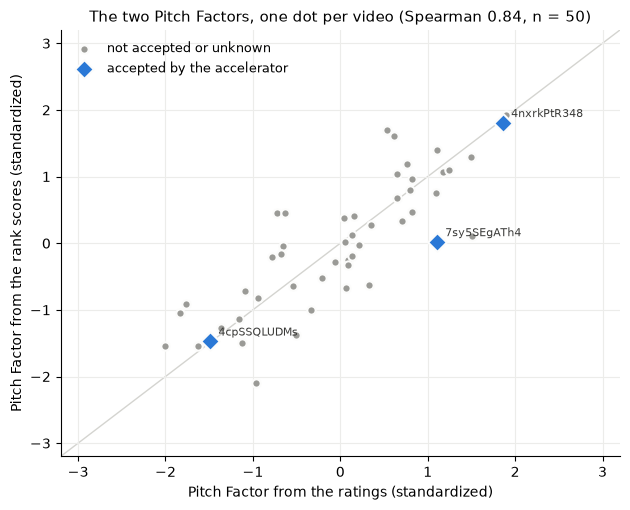

In [6]:
if "pitch_factor_methods_spearman" in S:
    s = S["pitch_factor_methods_spearman"]
    print(f"Spearman between the two Pitch Factors: {s['spearman']:.3f} (p = {s['p']:.3g}) over {s['videos']} videos.")
if not A.convergence.empty:
    display(A.convergence.set_index("code").round(3))
    weak = A.convergence[A.convergence["spearman"] < 0.5]["code"].tolist()
    print(f"Codes where the two methods agree at Spearman below 0.5: {', '.join(weak) or 'none'}.")
else:
    print("No ranking run was given, so there is nothing to compare the ratings with.")
fig = hm.pitch_factor_figure(A)
display(fig) if fig is not None else None

## 5. Against Hu & Ma's own Pitch Factor (convergent validity)

**What this shows.** Hu & Ma's Pitch Factor and ten features, computed with their code on the same videos
(`HU_MA_PITCH_FACTOR_CSV`), set against the two Stage A Pitch Factors. The first line checks that their file's
factor is the first component of its ten features. The first table gives, per Stage A method, the Pearson
correlation with a 95% interval, the Spearman and Kendall rank correlations, and the share of videos the two put
in the same tercile (chance: one third). The second table asks the same per dimension: how far the mean rating
and the rank score of each code order the videos like Hu & Ma's feature of the same name. The third compares
how each of the three factors weights the ten dimensions (its loadings), with the correlation between loading
vectors. Two figures: one dot per video for each Stage A method, and the loadings beside the per-dimension
agreement.

**Unit and denominator.** Videos in both Hu & Ma's file and the Stage A runs (the first line says how many).
The loading tables: the ten codes.

**What it does not show.** Hu & Ma's features are machine-extracted estimators (face, audio and word models),
not ratings, so a shared name does not make a shared construct: a low correlation on a dimension says the two
instruments see different things there, not which is right. Their factor is re-estimated on these videos, so its
loadings are not the paper's Table II (the researcher's reproduction of their loadings correlates with the
paper's at about 0.85). Agreement with their factor is convergent validity against another unvalidated
instrument, not validity against human judgment. Neither instrument is human-validated.


Hu & Ma's file: 50 videos, 50 matched to the Stage A runs; its Pitch Factor is the first component of its ten features (r = 1.000, variance share 29.3%).


,videos,pearson,pearson_low,pearson_high,pearson_p,spearman,spearman_p,kendall_tau,kendall_p,same_tercile_share
method,,,,,,,,,,
ratings,50,0.053,-0.228,0.327,0.713,0.048,0.741,0.032,0.744,0.28
ranks,50,0.001,-0.277,0.279,0.994,-0.009,0.948,-0.007,0.940,0.24


Pitch Factor (ratings) against Hu & Ma's: Pearson +0.05 (95% interval -0.23 to +0.33), Spearman +0.05, same tercile for 28% of 50 videos (chance 33%): the interval includes zero, so this sample shows no agreement at the factor level.
Pitch Factor (ranks) against Hu & Ma's: Pearson +0.00 (95% interval -0.28 to +0.28), Spearman -0.01, same tercile for 24% of 50 videos (chance 33%): the interval includes zero, so this sample shows no agreement at the factor level.


,videos,rating_spearman,rating_p,rank_score_spearman,rank_score_p,hu_ma_feature_sd,hu_ma_distinct_values
code,,,,,,,
visual_positive,50,0.61,0.00,0.62,0.00,0.18,50
visual_negative,50,-0.12,0.40,-0.06,0.70,0.12,50
vocal_arousal,50,0.14,0.32,0.11,0.44,0.28,42
vocal_valence,50,0.04,0.77,-0.01,0.96,0.25,35
vocal_positive,50,0.06,0.69,-0.02,0.89,0.41,50
vocal_negative,50,-0.04,0.78,-0.05,0.71,0.34,50
verbal_positive,50,0.57,0.00,0.49,0.00,0.01,35
verbal_negative,50,0.54,0.00,0.61,0.00,0.01,22
verbal_warmth,50,0.31,0.03,0.12,0.40,0.01,45


Dimensions where the mean rating and Hu & Ma's feature agree at |Spearman| of 0.5 or more: visual_positive, verbal_positive, verbal_negative; below 0.2: visual_negative, vocal_arousal, vocal_valence, vocal_positive, vocal_negative, verbal_ability.
Dimensions where the rank score and Hu & Ma's feature agree at |Spearman| of 0.5 or more: visual_positive, verbal_negative; below 0.2: visual_negative, vocal_arousal, vocal_valence, vocal_positive, vocal_negative, verbal_warmth, verbal_ability.


,loading_ratings,loading_ranks,loading_hu_ma
code,,,
visual_positive,0.88,0.96,0.24
visual_negative,-0.42,-0.91,-0.60
vocal_arousal,0.83,0.89,0.76
vocal_valence,0.73,0.82,0.84
vocal_positive,0.91,0.96,0.62
vocal_negative,-0.28,-0.92,-0.75
verbal_positive,0.49,0.55,-0.28
verbal_negative,-0.22,-0.34,0.28
verbal_warmth,0.35,0.59,-0.05


Correlation between loading vectors over the ten codes: ratings vs ranks 0.97, ratings vs hu_ma 0.76, ranks vs hu_ma 0.78.


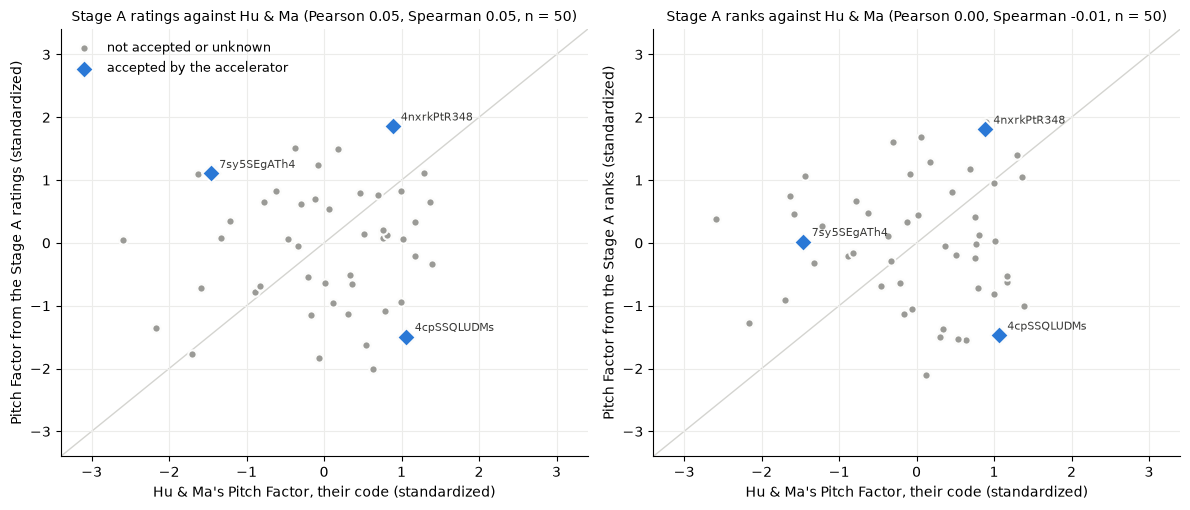

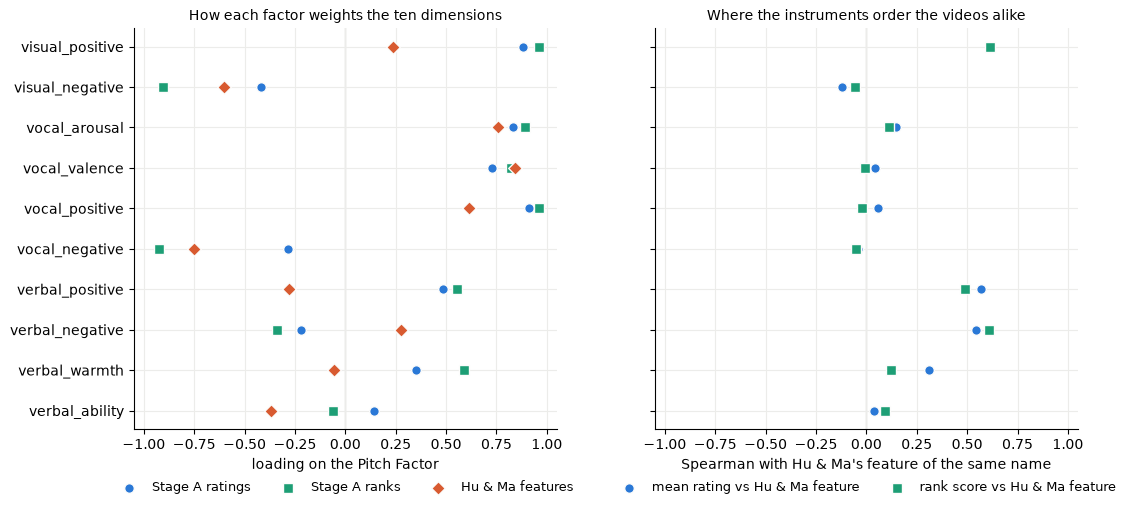

In [7]:
if A.hu_ma is None:
    print("No Hu & Ma Pitch Factor file was given (HU_MA_PITCH_FACTOR_CSV is None), so there is nothing to compare with.")
else:
    h = S["hu_ma_pitch_factor"]
    print(f"Hu & Ma's file: {h['videos_in_file']} videos, {h['videos_matched']} matched to the Stage A runs; "
          + (f"its Pitch Factor is the first component of its ten features (r = {h['reproduced_from_features_corr']:.3f}, "
             f"variance share {h['explained_variance_share']:.1%})." if "reproduced_from_features_corr" in h
             else f"its features could not be re-factored: {h.get('reproduced_error')}"))
    if A.external.empty:
        print("Too few videos in common to compare.")
    else:
        display(A.external.set_index("method").round(3))
        print("\n".join(hm.external_readings(A)))
        display(A.external_features.set_index("code").round(2))
        print("\n".join(hm.external_feature_readings(A)))
    display(A.loading_table.set_index("code").round(2))
    print("Correlation between loading vectors over the ten codes: "
          + ", ".join(f"{k.replace('_vs_', ' vs ')} {v:.2f}" for k, v in S["loading_correlations"].items()) + ".")
fig = hm.external_figure(A)
display(fig) if fig is not None else None
fig = hm.loading_figure(A)
display(fig) if fig is not None else None


## 6. The funding decision: Hu & Ma Table III and Table IV analogues

**What this shows.** Hu & Ma estimate a logit of *I(invested)* on the standardized Pitch Factor with accelerator
fixed effects and accelerator-year clustering and report the average marginal effect (0.030 per standard deviation
on 1,139 videos). The first table does the same for each Pitch Factor built above; the second does it one code at a
time (their Table IV). Each row gives: the **maximum-likelihood logit** average marginal effect with a
heteroskedasticity-robust standard error (their specification without the fixed effects); the **Firth** penalized
logit coefficient, which stays finite when a predictor separates the accepted videos, with and without
accelerator-family indicators; and the **AUC** (the probability an accepted video scores above a non-accepted one)
with an **exact** permutation p-value, found by enumerating every placement of the acceptances among the videos.

**Unit and denominator.** One row per predictor; the labelled videos with that measure (acceptance counts in the
`accepted` column). The last table repeats the headline numbers in words.

**What it does not show.** With a handful of acceptances none of these tests can detect an effect of Hu & Ma's size:
the exact test reaches p < 0.05 only when the accepted videos sit almost entirely above the rest. A row flagged
`separation` has no maximum-likelihood estimate; read its Firth and AUC columns. With twenty feature-level tests,
one below 0.05 is the chance rate. These tables show the procedure and point estimates, not evidence either way.

In [8]:
T3 = ["predictor", "n", "events", "ml_ame", "ml_ame_se", "ml_p", "ml_pseudo_r2", "firth_coef", "firth_se", "firth_p",
      "firth_ame", "firth_fe_coef", "firth_fe_p", "auc", "auc_p_exact", "ml_note"]
T4 = ["method", "code", "events", "ml_ame", "ml_ame_se", "ml_p", "firth_coef", "firth_p", "auc", "auc_p_exact",
      "mean_funded", "mean_not_funded", "ml_note"]
if A.table3.empty:
    print("Not estimable: the labelled videos include no acceptance, or no rejection, or no measure.")
else:
    display(A.table3[[c for c in T3 if c in A.table3.columns]].set_index("predictor").round(3))
    display(A.table4[[c for c in T4 if c in A.table4.columns]].set_index(["method", "code"]).round(3))
    for row in A.table3.to_dict(orient="records"):
        print(f"{row['predictor']}: a one-SD increase changes the accepted probability by {row['ml_ame']:+.3f} "
              f"(SE {row['ml_ame_se']:.3f}, p {row['ml_p']:.2f}); Firth coefficient {row['firth_coef']:+.2f} (p {row['firth_p']:.2f}); "
              f"AUC {row['auc']:.2f} (exact p {row['auc_p_exact']:.2f}){'; ' + row['ml_note'] if row.get('ml_note') else ''}.")
    hits = A.table4[A.table4["auc_p_exact"] < 0.05]
    print(f"Feature-level rows with exact p below 0.05: {len(hits)} of {len(A.table4)}"
          + (": " + ", ".join(f"{r.code} ({r.method})" for r in hits.itertuples()) if len(hits) else "") + ".")

,n,events,ml_ame,ml_ame_se,ml_p,ml_pseudo_r2,firth_coef,firth_se,firth_p,firth_ame,firth_fe_coef,firth_fe_p,auc,auc_p_exact,ml_note
predictor,,,,,,,,,,,,,,,
Pitch Factor (ratings),49,3,0.034,0.058,0.554,0.040,0.492,0.577,0.394,0.035,0.505,0.362,0.652,0.411,
Pitch Factor (ranks),49,3,0.009,0.046,0.847,0.003,0.138,0.537,0.797,0.010,0.149,0.770,0.529,0.891,
Pitch Factor (Hu & Ma),49,3,0.009,0.045,0.844,0.003,0.027,0.541,0.960,0.002,0.102,0.848,0.601,0.593,


events  ml_ame  ml_ame_se   ml_p  firth_coef  firth_p    auc  auc_p_exact  mean_funded  mean_not_funded                                            ml_note
method          code                                                                                                                                                                       
rating          visual_positive       3   0.033      0.035  0.345       0.555    0.278  0.645        0.421        3.133            2.578                                                   
                visual_negative       3   0.031      0.024  0.193       0.576    0.126  0.605        0.167        1.400            1.109                                                   
                vocal_arousal         3   0.002      0.059  0.980      -0.086    0.869  0.565        0.707        2.667            2.648                                                   
                vocal_valence         3   0.034      0.044  0.444       0.462    0.426  0.652        0.438        3.667            3.404                                                   
                vocal_positive        3   0.024      0.048  0.617       0.364    0.505  0.609        0.545        2.667            2.287                                                   
                vocal_negative        3     NaN        NaN    NaN       0.156    0.712  0.457        1.000        1.000            1.057  did not converge; quasi-complete separation; M...
                verbal_positive       3   0.092      0.054  0.090       1.508    0.075  0.822        0.055        3.600            2.665                                                   
                verbal_negative       3  -0.057      0.049  0.246      -0.693    0.306  0.297        0.284        1.333            1.948                                                   
                verbal_warmth         3   0.010      0.020  0.621       0.218    0.673  0.576        0.734        2.667            2.513                                                   
                verbal_ability        3   0.073      0.045  0.101       1.215    0.067  0.783        0.108        4.267            3.135                                                   
rank score      visual_positive       3   0.004      0.046  0.934       0.081    0.880  0.471        0.891        0.118           -0.041                                                   
                visual_negative       3  -0.016      0.041  0.705      -0.257    0.631  0.522        0.922       -0.421            0.141                                                   
                vocal_arousal         3   0.000      0.048  0.992       0.035    0.948  0.500        1.000        0.002           -0.016                                                   
                vocal_valence         3  -0.038      0.037  0.313      -0.601    0.281  0.384        0.538       -1.172            0.055                                                   
                vocal_positive        3   0.003      0.051  0.953       0.056    0.916  0.529        0.891        0.090           -0.036                                                   
                vocal_negative        3  -0.021      0.042  0.606      -0.337    0.534  0.471        0.891       -0.617            0.147                                                   
                verbal_positive       3   0.098      0.041  0.018       1.766    0.040  0.891        0.019        3.345           -0.177                                                   
                verbal_negative       3  -0.046      0.036  0.196      -0.715    0.221  0.268        0.200       -1.772            0.230                                                   
                verbal_warmth         3  -0.021      0.033  0.527      -0.341    0.524  0.435        0.738       -0.772            0.077                                                   
                verbal_ability        3   0.080      0.045  0.078       1.383    0.04

Pitch Factor (ratings): a one-SD increase changes the accepted probability by +0.034 (SE 0.058, p 0.55); Firth coefficient +0.49 (p 0.39); AUC 0.65 (exact p 0.41).
Pitch Factor (ranks): a one-SD increase changes the accepted probability by +0.009 (SE 0.046, p 0.85); Firth coefficient +0.14 (p 0.80); AUC 0.53 (exact p 0.89).
Pitch Factor (Hu & Ma): a one-SD increase changes the accepted probability by +0.009 (SE 0.045, p 0.84); Firth coefficient +0.03 (p 0.96); AUC 0.60 (exact p 0.59).
Feature-level rows with exact p below 0.05: 2 of 30: verbal_positive (rank score), verbal_ability (rank score).


## 7. Export

With `EXPORT = True`, the tables of sections 2 to 6 and a Markdown summary are written to
`runs/<rating run>/analysis/<ANALYSIS_ID>/`; the committed exports from the script live in
`runs/<rating run>/analysis/hu_ma_funding/`. Nothing else is ever written.

In [9]:
if EXPORT:
    out_dir = STAGE_A_RUN / "analysis" / ANALYSIS_ID
    hm.write(A, out_dir)
    print(f"Written: {out_dir}")
    print("\n".join(sorted(p.name for p in out_dir.iterdir())))
else:
    print("EXPORT is False: nothing was written.")

EXPORT is False: nothing was written.
